# Part 5-1. Pruning for LLM

## Goals

본 실습에서는 대규모 언어 모델(Large Language Model, LLM)의 크기를 효과적으로 줄이는 Pruning 기법을 학습합니다. 특히 Magnitude-based pruning과 최근 주목받는 Wanda 기법을 활용하여, 파라미터의 수를 효율적으로 감소시키면서 모델의 성능을 유지하는 방법을 실습합니다.


## Contents

1. **Magnitude-based Pruning 실습**:
   - 간단한 magnitude 기반 pruning 방법을 통해 모델 크기를 감소시키고 성능 변화를 확인합니다.
2. **Wanda를 이용한 Pruning 실습**:
   - Activation의 중요도를 측정하여 더 정교하게 pruning을 수행하는 Wanda 방법을 구현하고 모델의 성능을 비교합니다.

## Setup

필요한 모듈을 불러옵니다.

In [58]:
import tqdm
import torch
from torch import nn
from transformers import AutoModelForCausalLM, AutoTokenizer
from datasets import load_dataset
from functools import partial
import gc
import os

### 모델 평가

Wikitext-2 데이터셋을 사용하여 모델의 성능을 평가하는 지표인 perplexity를 계산합니다.

**Perplexity란?**
- Perplexity는 언어 모델이 주어진 텍스트를 얼마나 잘 예측하는지를 수치로 나타낸 지표입니다.
- 수학적으로는 모델이 예측한 확률분포의 "불확실성"을 측정하는 값이며, 값이 **낮을수록 모델의 성능이 좋다**고 해석합니다.
- 단어 $\{w_1, w_2, w_3, ..., w_N\}$으로 구성된 문장의 Perplexity는 다음과 같은 수식으로 나타낼 수 있습니다.
    - $Perplexity = \sqrt[N]{\frac{1}{\prod_{i=1}^{N} P(w_i | w_1, w_2, ..., w_{i-1})}}$
    - 여기서 $P(w_i | w_1, w_2, ..., w_{i-1})$은 $i$번째에 $w_i$ 단어를 생성할 확률을 의미합니다.
    - 즉, Perplexity는 문자의 발생 확률에 대한 역수를 의미하게 됩니다.
- 직관적으로 Perplexity가 10이라면 모델이 다음 단어 후보를 10개 정도로 생각하고 있다고 볼 수 있습니다.

In [59]:
def evaluate(model, tokenizer):
    """
    모델의 perplexity를 계산하는 함수입니다.

    Args:
        model: 평가할 모델
        tokenizer: 토크나이저

    Returns:
        float: 계산된 perplexity 값
    """
    # 테스트 데이터셋 로드 및 전처리
    testenc = load_dataset('Salesforce/wikitext', 'wikitext-2-raw-v1', split='test')
    testenc = tokenizer("\n\n".join(testenc['text']), return_tensors='pt')

    # 입력 데이터를 모델 디바이스로 이동
    testenc = testenc.input_ids.to(model.device)
    nsamples = 40
    model = model.eval()  # 평가 모드로 설정

    # Negative log likelihood 계산
    nlls = []
    for i in tqdm.tqdm(range(nsamples), desc="evaluating..."):
        # 배치 데이터 준비
        batch = testenc[:, (i * 2048):((i + 1) * 2048)].to(model.device)

        # 모델 추론
        with torch.no_grad():
            lm_logits = model(batch).logits

        # 로짓과 레이블 시프트
        shift_logits = lm_logits[:, :-1, :].contiguous().float()
        shift_labels = testenc[:, (i * 2048):((i + 1) * 2048)][:, 1:]

        # 손실 계산
        loss_fct = nn.CrossEntropyLoss()
        loss = loss_fct(shift_logits.view(-1, shift_logits.size(-1)), shift_labels.view(-1))
        neg_log_likelihood = loss.float() * 2048
        nlls.append(neg_log_likelihood)

    # Perplexity 계산 및 반환
    return torch.exp(torch.stack(nlls).sum() / (nsamples * 2048))

### SmolLM-135M 모델 로딩

SmolLM-135M 모델을 로딩하고 평가합니다.
여기서 tokenizer는 텍스트(문장)를 모델이 이해할 수 있는 작은 단위(token)로 나누는 역할을 수행합니다.

In [60]:
model_path = "HuggingFaceTB/SmolLM-135M"
os.environ["HF_HOME"] = "D:\\data\\hf_cache"
tokenizer = AutoTokenizer.from_pretrained(model_path, use_fast=False)
model = AutoModelForCausalLM.from_pretrained(model_path, device_map="auto", torch_dtype=torch.float16, use_safetensors=True)

# Evaluate the model
model_perplexity = evaluate(model, tokenizer)
print(f"\nmodel perplexity: {model_perplexity:.2f}")

tokenizer_config.json: 0.00B [00:00, ?B/s]

C:\Users\swsuser-k51\AppData\Roaming\Python\Python312\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\swsuser-k51\.cache\huggingface\hub\models--HuggingFaceTB--SmolLM-135M. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/831 [00:00<?, ?B/s]

...

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

evaluating...: 100%|███████████████████████████████████████████████████████████████████| 40/40 [00:13<00:00,  3.05it/s]


model perplexity: 16.54


## [실습 1] Magnitude-based Pruning 구현

Magnitude-based pruning 함수를 구현하세요. 구현은 CNN에서 magnitude-based pruning을 구현하는 방식과 유사합니다.

In [61]:
@torch.no_grad()
def prune_magnitude(model, sparsity):
    for n, m in model.named_modules():
        if isinstance(m, nn.Linear) and "lm_head" not in n:
            W = m.weight.data
            ##################### YOUR CODE STARTS HERE #####################
            num_elements = W.numel()
            num_zeros = round(num_elements * sparsity)
            importance = torch.abs(W)
            threshold = torch.kthvalue(importance.flatten(), num_zeros)[0]
            mask = importance > threshold
            ##################### YOUR CODE ENDS HERE #######################
            W.mul_(mask)

Pruning된 모델을 평가합니다.

In [62]:
gc.collect()
torch.cuda.empty_cache()
model = AutoModelForCausalLM.from_pretrained(model_path, device_map="auto", torch_dtype=torch.float16, use_safetensors=True)
prune_magnitude(model, 0.5)

# Evaluate the model
model_perplexity = evaluate(model, tokenizer)
print(f"\nmodel perplexity (magnitude 50%): {model_perplexity:.2f}")

evaluating...: 100%|███████████████████████████████████████████████████████████████████| 40/40 [00:13<00:00,  3.03it/s]


model perplexity (magnitude 50%): 2208.16


## [실습 2] Calibration 데이터셋 준비

[Wanda](https://arxiv.org/pdf/2306.11695)를 사용하여 importance를 계산하기 위해서는 calibration 데이터셋을 통해 activation을 추출해야 합니다.

이를 위해 ```get_calib_dataset``` 함수는 calibration dataset을 준비합니다.

In [63]:
def get_calib_dataset(tokenizer=None, n_samples=256, block_size=512):
    dataset = load_dataset("mit-han-lab/pile-val-backup", split="validation")
    dataset = dataset.shuffle(seed=42)
    samples = []
    n_run = 0
    for data in dataset:
        line = data["text"]
        line = line.strip()
        line_encoded = tokenizer.encode(line)
        if len(line_encoded) > block_size:
            continue
        sample = torch.tensor([line_encoded])
        if sample.numel() == 0:
            continue
        samples.append(sample)
        n_run += 1
        if n_run == n_samples:
            break

    # now concatenate all samples and split according to block size
    cat_samples = torch.cat(samples, dim=1)
    n_split = cat_samples.shape[1] // block_size
    print(f" * Split into {n_split} blocks")
    return [cat_samples[:, i*block_size:(i+1)*block_size] for i in range(n_split)]

samples = get_calib_dataset(tokenizer)

README.md:   0%|          | 0.00/167 [00:00<?, ?B/s]

C:\Users\swsuser-k51\AppData\Roaming\Python\Python312\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\swsuser-k51\.cache\huggingface\hub\datasets--mit-han-lab--pile-val-backup. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Repo card metadata block was not found. Setting CardData to empty.


val.jsonl.zst:   0%|          | 0.00/471M [00:00<?, ?B/s]

Generating validation split:   0%|          | 0/214670 [00:00<?, ? examples/s]

 * Split into 126 blocks


아래 빈칸을 작성하여 `activation_norm`을 계산하세요.
Wanda 기법에서는 `activation_norm`을 L2 norm으로 계산하지만, 구현에서는 calibration 데이터셋에 대해 여러 번 반복하여 누적하므로
`activation_norm` 계산 시 제곱을 적용한 형태로 누적합니다. (이후 값을 사용할 때는 제곱근을 적용해야 합니다.)

In [64]:
@torch.no_grad()
def get_calib_feat(model, tokenizer, samples):
    input_dict = dict()
    nsamples_dict = dict()
    def add_batch(m, x, y, name):
        if name not in input_dict:
            input_dict[name] = torch.zeros((m.weight.data.shape[1]), device=m.weight.data.device)
            nsamples_dict[name] = 0

        if isinstance(x, tuple):
            x = x[0]

        if len(x.shape) == 2:
            x = x.unsqueeze(0)
        tmp = x.shape[0]
        if len(x.shape) == 3:
            x = x.reshape((-1, x.shape[-1]))
        x = x.t()

        input_dict[name] *= nsamples_dict[name] / (nsamples_dict[name] + tmp)
        nsamples_dict[name] += tmp

        x = x.type(torch.float32)
        ##################### YOUR CODE STARTS HERE #####################
        # activation_norm을 계산하세요.
        # x.shape => (hidden_size, batch_size)
        activation_norm = torch.norm(x, p=2, dim=1) ** 2
        # activation_norm.shape => (hidden_size)
        ##################### YOUR CODE ENDS HERE #######################
        input_dict[name] += activation_norm / nsamples_dict[name]

    hooks = []
    for name, m in model.named_modules():
        if isinstance(m, nn.Linear) and "lm_head" not in name:
            hooks.append(
                m.register_forward_hook(
                    partial(add_batch, name=name)))

    print("Collecting norm of input activations...")
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    pbar = tqdm.tqdm(samples)
    for input_ids in pbar:
        input_ids = input_ids.to(device)
        model(input_ids)

    for key in input_dict.keys():
        input_dict[key].sqrt_()

    for hook in hooks:
        hook.remove()
    return input_dict

In [65]:
gc.collect()
torch.cuda.empty_cache()
model = AutoModelForCausalLM.from_pretrained(model_path, device_map="auto", torch_dtype=torch.float16, use_safetensors=True)
input_feat = get_calib_feat(model, tokenizer, samples)

100%|████████████████████████████████████████████████████████████████████████████████| 126/126 [00:16<00:00,  7.65it/s]


## [실습 3] Wanda Pruning 구현

Wanda 논문을 참고하여 아래 빈 칸을 채워 Wanda Pruning을 구현하고 실행해보세요.

Wanda에서는 일반적인 magnitude-based pruning 방법과 다르게게 weight parameter의 행(row)별로 동일한 희소성(sparsity)으로 pruning을 진행합니다.

In [66]:
@torch.no_grad()
def prune_wanda(model, sparsity, input_feat):
    for n, m in model.named_modules():
        if isinstance(m, nn.Linear) and "lm_head" not in n:
            W = m.weight.data
            ##################### YOUR CODE STARTS HERE #####################
            row, col = W.shape
            num_zeros_per_row = round(col * sparsity)
            importance = torch.abs(W) * input_feat[n]
            threshold = torch.kthvalue(importance, num_zeros_per_row, dim=1)[0]
            mask = importance > threshold.reshape(row, 1)
            ##################### YOUR CODE ENDS HERE #######################
            W.mul_(mask)

In [67]:
gc.collect()
torch.cuda.empty_cache()
model = AutoModelForCausalLM.from_pretrained(model_path, device_map="auto", torch_dtype=torch.float16, use_safetensors=True)
prune_wanda(model, sparsity=0.5, input_feat=input_feat)

# Evaluate the model
model_perplexity = evaluate(model, tokenizer)
print(f"\nmodel perplexity (wanda 50%): {model_perplexity:.2f}")

evaluating...: 100%|███████████████████████████████████████████████████████████████████| 40/40 [00:12<00:00,  3.13it/s]


model perplexity (wanda 50%): 37.44


---

# Part 5-2. Speculative Decoding 기초

Autoregressive decoding은 토큰 하나를 뽑을 때마다 모델 전체 weight를 한 번씩 읽어야 합니다.
배치가 1일 때 GPU 연산 유닛은 거의 놀고 있고, **메모리 대역폭만 소진**됩니다.

Speculative Decoding(SD)의 아이디어:

1. **Draft** — 값싼 모델이 앞으로 나올 $\gamma$개 토큰을 추측한다.
2. **Verify** — target 모델이 그 $\gamma$개를 **한 번의 forward로 동시에** 채점한다.
3. 앞에서부터 일치하는 만큼 받아들이고, 처음 틀린 자리에는 **target 자신의 예측**을 넣는다.

3번 때문에 SD는 **lossless**입니다. greedy decoding이라면 출력이 AR decoding과 **토큰 단위로 완전히 동일**합니다.
(샘플링에서는 rejection sampling으로 target 분포가 정확히 보존됩니다.)
Quantization/Pruning과 성질이 근본적으로 다른 지점입니다.

속도 모델은 다음과 같습니다.

$$
\text{speedup} \approx \frac{\tau}{1 + c\,\gamma}
$$

- $\tau$ : 라운드당 평균 수락 토큰 수 (acceptance length)
- $c$ : target 대비 drafter의 비용 비율

**$\tau$만 키우면 되는 것이 아니라 drafting 비용이 분모에 있다** — 이 식이 Part 4, 5 전체를 관통합니다.

In [18]:
import os
import torch
import transformers
import math
import matplotlib.pyplot as plt
import random
import torch.nn.functional as F
import time

from transformers import AutoTokenizer, AutoModelForCausalLM

DEVICE = "cuda"
DTYPE = torch.float16

print("Transformers:", transformers.__version__)
print("GPU:", torch.cuda.get_device_name(0))

Transformers: 4.57.6
GPU: Tesla T4


In [19]:
# =====================================================================
# 실습에 사용할 모델 다운로드
# =====================================================================

import os
from huggingface_hub import snapshot_download

MODEL_ROOT = "/content/models"
os.makedirs(MODEL_ROOT, exist_ok=True)

MODEL_PATHS = {
    "target": {
        "repo": "Qwen/Qwen3-4B",
        "path": f"{MODEL_ROOT}/Qwen3-4B",
    },
    "vanilla_draft": {
        "repo": "Qwen/Qwen3-0.6B",
        "path": f"{MODEL_ROOT}/Qwen3-0.6B",
    },
    "eagle3_draft": {
        "repo": "AngelSlim/Qwen3-4B_eagle3",
        "path": f"{MODEL_ROOT}/Qwen3-4B_eagle3",
    },
    "dflash_draft": {
        "repo": "z-lab/Qwen3-4B-DFlash-b16",
        "path": f"{MODEL_ROOT}/Qwen3-4B-DFlash-b16",
    },
}

for name, info in MODEL_PATHS.items():
    print(f"Downloading {name}...")

    snapshot_download(
        repo_id=info["repo"],
        local_dir=info["path"],
    )

print("\nAll models downloaded.")

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]


All models downloaded.


In [20]:
# =====================================================================
# 3-0. Target / Draft 모델 로드
# =====================================================================

from transformers import AutoTokenizer, AutoModelForCausalLM
import torch

TARGET_DIR = "/content/models/Qwen3-4B"
DRAFT_DIR  = "/content/models/Qwen3-0.6B"

DTYPE = torch.float16

# Tokenizer
sd_tokenizer = AutoTokenizer.from_pretrained(TARGET_DIR)

# Target model
target_model = AutoModelForCausalLM.from_pretrained(
    TARGET_DIR,
    dtype=DTYPE,
    attn_implementation="sdpa",
).to(DEVICE).eval()

# Draft model
draft_model = AutoModelForCausalLM.from_pretrained(
    DRAFT_DIR,
    dtype=DTYPE,
    attn_implementation="sdpa",
).to(DEVICE).eval()

EOS = sd_tokenizer.eos_token_id

print("Target :", TARGET_DIR)
print("Draft  :", DRAFT_DIR)
print(f"VRAM   : {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

Target : /content/models/Qwen3-4B
Draft  : /content/models/Qwen3-0.6B
VRAM   : 8.67 GB


In [21]:
# =====================================================================
# 3-1. 평가용 프롬프트와 AR Baseline
# =====================================================================

PROMPT = "Write a Python function that reverses a linked list."
MAX_NEW = 128
EOS = sd_tokenizer.eos_token_id

ids = sd_tokenizer.apply_chat_template(
  [{"role": "user", "content": PROMPT}],
  tokenize=True,
  add_generation_prompt=True,
  enable_thinking=False,
  return_tensors="pt",
  return_dict=True
)["input_ids"].to(DEVICE)


# ---------------------------------------------------------------------
# 한 token을 생성하는 공통 함수
# ---------------------------------------------------------------------

@torch.inference_mode()
def greedy_step(model, token, cache):

  out = model(
    token,
    past_key_values=cache,
    use_cache=True
  )

  next_token = out.logits[:, -1].argmax(-1, keepdim=True)

  return next_token, out.past_key_values


# ---------------------------------------------------------------------
# AR Baseline
# ---------------------------------------------------------------------

@torch.inference_mode()
def greedy_decode(model, ids, max_new_tokens):
  output = ids.clone()

  # 마지막 prompt token 직전까지 Prefill
  prefix = ids[:, :-1]
  cache = model(prefix, use_cache=True).past_key_values

  # 마지막 prompt token부터 Decode 시작
  token = ids[:, -1:]

  torch.cuda.synchronize()
  start = time.perf_counter()

  n_new = 0

  for _ in range(max_new_tokens):

    token, cache = greedy_step(
      model,
      token,
      cache
    )

    output = torch.cat([output, token], dim=-1)
    n_new += 1

    if token.item() == EOS:
      break

  torch.cuda.synchronize()
  decode_time = time.perf_counter() - start

  return output, decode_time, n_new

In [22]:
# =====================================================================
# AR Baseline 실행: Decode-only TPS
# =====================================================================

ar_out, decode_time, decode_tokens = greedy_decode(
  target_model,
  ids,
  MAX_NEW
)

ar_tps = decode_tokens / decode_time

text = sd_tokenizer.decode(
  ar_out[0, ids.shape[1]:],
  skip_special_tokens=True
)

print(f"[AR Decode] {decode_tokens} tokens / {decode_time:.2f}s = {ar_tps:.1f} tok/s")
print(text)

[AR Decode] 128 tokens / 12.49s = 10.2 tok/s
Sure! Here's a Python function that reverses a **linked list**. We'll assume that the linked list is represented using a `Node` class, where each node has a `value` and a `next` pointer.

### Step 1: Define the Node class

```python
class Node:
    def __init__(self, value):
        self.value = value
        self.next = None
```

### Step 2: Define the function to reverse the linked list

```python
def reverse_linked_list(head):
    prev = None
    current = head

    while current:
        next_node = current


## [실습 6] Vanilla Speculative Decoding 구현

한 라운드의 흐름입니다. (`n_committed` = 현재까지 확정된 토큰 수)

```
draft : d1, d2, ..., dγ 를 순차적으로 γ번 forward 하여 생성
target: [마지막 확정 토큰, d1, ..., dγ] 를 한 번의 forward로 처리
        -> preds[0..γ] 를 얻음 (preds[j] = d1..dj 를 봤을 때 target의 다음 토큰 예측)
accept: preds[j] == d_{j+1} 인 동안 전진, n개 수락
commit: d1..dn  +  preds[n]   (마지막 하나는 target 자신의 토큰이므로 항상 정답)
cache : 두 캐시를 모두 n_committed + n 길이로 롤백
```

**주의**: 라운드마다 최소 1개(`preds[n]`)는 반드시 확정되므로 무한 루프가 생기지 않습니다.
캐시 롤백(`crop_cache`)을 빠뜨리면 이후 출력이 깨지므로 반드시 넣어야 합니다.

In [23]:
# =====================================================================
# 3-2. Draft Generation
# =====================================================================

@torch.inference_mode()
def draft_tokens(model, x, cache, gamma):
  tokens = []

  ######################### 실습 시작 ########################

  # TODO: 다음 draft token을 생성하세요.
  # HINT: greedy_step()을 사용해 draft token을 gamma개 순차적으로 생성하세요.
  for _ in range(gamma):
    x, cache = greedy_step(model, x, cache)
    tokens.append(x)

  ######################### 실습 끝 ########################

  return torch.cat(tokens, dim=-1), cache


# =====================================================================
# 3-3. Target Verification
# =====================================================================

@torch.inference_mode()
def verify_draft(target, x, drafted, cache):

  ######################### 실습 시작 ########################

  # TODO : 마지막 committed token과 draft token들을 하나의 sequence로 연결하세요.
  # HINT: torch.cat()을 사용해 마지막 committed token과 draft token들을 sequence 방향으로 연결하세요.
  verify_ids = torch.cat([x, drafted], dim=-1)

  result = target(
    verify_ids,
    past_key_values=cache,
    use_cache=True
  )

  preds = result.logits[0].argmax(-1)

  ######################### 실습 끝 ########################

  return preds, result.past_key_values

In [24]:
# =====================================================================
# 3-4. Accept / Reject
# =====================================================================

def accept_draft(drafted, preds, gamma):

  ######################### 실습 시작 ########################

  #TODO: Draft와 Target prediction을 앞에서부터 비교하고 첫 mismatch에서 멈추세요.
  n = 0
  for i in range(gamma):
    if drafted[0, i] == preds[i]:
      n += 1
    else:
      break

  # HINT: accept된 draft token 뒤에 Target의 prediction 하나를 추가하세요.
  new_tokens = torch.cat([drafted[:, :n],preds[n].view(1, 1)],dim=1)

  ######################### 실습 끝 ########################

  return new_tokens, n

In [25]:
# =====================================================================
# 3-5. Speculative Decoding
# =====================================================================

@torch.inference_mode()
def speculative_decode(target, draft, ids, gamma=4, max_new_tokens=MAX_NEW):
  out = ids.clone()

  # Prefill
  prefix = ids[:, :-1]
  tc = target(prefix, use_cache=True).past_key_values
  dc = draft(prefix, use_cache=True).past_key_values

  n_new, rounds = 0, 0

  torch.cuda.synchronize()
  start = time.perf_counter()

  while n_new < max_new_tokens:

    # 1) Draft
    x = out[:, dc.get_seq_length():]
    drafted, dc = draft_tokens(draft, x, dc, gamma)

    # 2) Verify
    x = out[:, tc.get_seq_length():]
    preds, tc = verify_draft(target, x, drafted, tc)

    # 3) Accept / Reject
    new_tokens, n = accept_draft(drafted, preds, gamma)

    # 생성 길이 제한
    new_tokens = new_tokens[:, :max_new_tokens - n_new]
    out = torch.cat([out, new_tokens], dim=1)

    n_new += new_tokens.shape[1]
    rounds += 1

    # Reject된 token의 KV 제거
    keep_len = out.shape[1] - 1

    for cache in (tc, dc):
      if cache.get_seq_length() > keep_len:
        cache.crop(keep_len - cache.get_seq_length())

    if (new_tokens == EOS).any():
      break

  torch.cuda.synchronize()
  decode_time = time.perf_counter() - start

  return out, n_new / rounds, rounds, decode_time

In [26]:
# =====================================================================
# 3-6. AR vs Speculative Decoding
# =====================================================================

GAMMA = 4

# 1) Autoregressive Decoding
ar_out, ar_time, ar_tokens = greedy_decode(
  target_model,
  ids,
  MAX_NEW
)

ar_tps = ar_tokens / ar_time


# 2) Speculative Decoding
sd_out, tau, rounds, sd_time = speculative_decode(
  target_model,
  draft_model,
  ids,
  gamma=GAMMA,
  max_new_tokens=MAX_NEW
)

sd_tokens = sd_out.shape[1] - ids.shape[1]
sd_tps = sd_tokens / sd_time


# 3) 결과 비교
print(f"Gamma            : {GAMMA}")
print(f"AR TPS           : {ar_tps:.1f} tok/s")
print(f"SD TPS           : {sd_tps:.1f} tok/s")
print(f"Speedup          : {sd_tps / ar_tps:.2f}x")
print(f"Avg tokens/round : {tau:.2f}")
print(f"Target rounds    : {rounds}")
print(f"Identical output : {torch.equal(ar_out, sd_out)}")

print("\n[Output]")
print(
  sd_tokenizer.decode(
    sd_out[0, ids.shape[1]:],
    skip_special_tokens=True
  )
)

Gamma            : 4
AR TPS           : 9.9 tok/s
SD TPS           : 8.8 tok/s
Speedup          : 0.90x
Avg tokens/round : 3.76
Target rounds    : 34
Identical output : True

[Output]
Sure! Here's a Python function that reverses a **linked list**. We'll assume that the linked list is represented using a `Node` class, where each node has a `value` and a `next` pointer.

### Step 1: Define the Node class

```python
class Node:
    def __init__(self, value):
        self.value = value
        self.next = None
```

### Step 2: Define the function to reverse the linked list

```python
def reverse_linked_list(head):
    prev = None
    current = head

    while current:
        next_node = current


Gamma= 1 | Avg tokens/round=1.86 | TPS=10.4
Gamma= 2 | Avg tokens/round=2.51 | TPS=10.7
Gamma= 4 | Avg tokens/round=3.76 | TPS=10.0
Gamma= 6 | Avg tokens/round=4.57 | TPS=8.8
Gamma= 8 | Avg tokens/round=4.92 | TPS=7.4


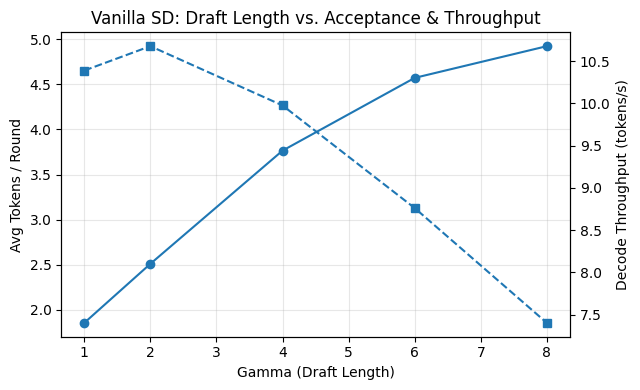

In [27]:
# =====================================================================
# 3-7. Gamma Sweep: Avg Tokens/Round와 Decode TPS 비교
# =====================================================================

gammas = [1, 2, 4, 6, 8]

avg_tokens = []
tpss = []

for gamma in gammas:

  # Warm-up
  _ = speculative_decode(
    target_model,
    draft_model,
    ids,
    gamma=gamma,
    max_new_tokens=8
  )

  # Speculative Decoding 측정
  out, tau, rounds, decode_time = speculative_decode(
    target_model,
    draft_model,
    ids,
    gamma=gamma,
    max_new_tokens=MAX_NEW
  )

  n_new = out.shape[1] - ids.shape[1]
  tps = n_new / decode_time

  avg_tokens.append(tau)
  tpss.append(tps)

  print(
    f"Gamma={gamma:>2} | "
    f"Avg tokens/round={tau:.2f} | "
    f"TPS={tps:.1f}"
  )


# =====================================================================
# Plot
# =====================================================================

fig, ax1 = plt.subplots(figsize=(6.5, 4))

# Target verification 한 번당 확정되는 token 수
ax1.plot(gammas, avg_tokens, "o-")
ax1.set_xlabel("Gamma (Draft Length)")
ax1.set_ylabel("Avg Tokens / Round")
ax1.grid(alpha=0.3)

# Decode throughput
ax2 = ax1.twinx()
ax2.plot(gammas, tpss, "s--")
ax2.set_ylabel("Decode Throughput (tokens/s)")

plt.title("Vanilla SD: Draft Length vs. Acceptance & Throughput")
plt.tight_layout()
plt.show()

In [30]:
# =====================================================================
# Part 3 종료: GPU 메모리 정리
# =====================================================================

import gc

if "target_model" in globals():
    del target_model

if "draft_model" in globals():
    del draft_model

gc.collect()
torch.cuda.empty_cache()

print(f"VRAM after cleanup: {torch.cuda.memory_allocated()/1024**3:.2f} GB")

VRAM after cleanup: 0.01 GB


---

# Part 4. EAGLE 계열: Tree Drafting

Vanilla SD는 draft를 **하나의 사슬(chain)** 로만 만듭니다. 중간에 한 번 틀리면 뒤는 전부 버려집니다.
EAGLE 계열은 대신 **여러 후보 경로를 트리로 묶어 한 번에 검증**합니다.

| | drafting 대상 | 트리 | 특징 |
|---|---|---|---|
| EAGLE-1 | feature(hidden state) 공간 | 정적 트리 | token 대신 feature를 예측 + shifted token으로 불확실성 보정 |
| EAGLE-2 | feature | **동적 트리** | drafter의 confidence로 문맥마다 다른 트리 구성 |
| EAGLE-3 | **다층 fused feature → token 직접 예측** | 동적 트리 | feature 예측 제약 제거, 학습 데이터 스케일링에 잘 반응 |

**트리 검증의 핵심 두 가지**

1. **Ancestor-only attention mask** — 트리의 모든 노드를 한 시퀀스로 펼쳐 넣되,
   각 노드는 자기 **조상 노드만** 볼 수 있어야 합니다. 형제/사촌을 보면 안 됩니다.
2. **노드별 position_ids** — 위치는 시퀀스에서의 순서가 아니라 **트리에서의 깊이**를 따릅니다.

> **본 실습의 범위**: EAGLE의 feature-level drafter는 별도 학습된 체크포인트가 필요합니다.
> 여기서는 drafter를 일반 소형 LM으로 대체하고, **채점 대상인 트리 구성/마스크/검증 로직**은
> 실제 EAGLE-2와 동일하게 구현합니다. 실제 체크포인트로 확장하려면
> `AngelSlim/Qwen3-4B_eagle3` + `github.com/SafeAILab/EAGLE`을 참고하세요.

## [실습 7-A] Tree attention mask와 position_ids

트리를 다음과 같이 표현합니다.

- `tokens[i]` : 노드 i의 토큰 id
- `parent[i]` : 부모 노드의 인덱스. `-1`이면 부모가 **prefix의 마지막 토큰(anchor)** 입니다.
- `depth[i]`  : 루트로부터의 깊이 (1부터 시작)
- 노드는 항상 **부모가 자식보다 먼저** 오도록 정렬되어 있습니다.

KV는 `[prefix 0..prefix_len-1] + [node 0..N-1]` 순서로 놓입니다.
additive mask이므로 **허용은 0.0, 금지는 dtype의 최솟값**을 넣습니다.

In [33]:
import os

print("현재 작업 경로:", os.getcwd())
print("다운로드 경로:", os.path.abspath("/content/models"))
print("모델 존재:", os.path.exists("/content/models/Qwen3-4B"))
print("config 존재:", os.path.isfile("/content/models/Qwen3-4B/config.json"))

현재 작업 경로: C:\Users\swsuser-k51\Downloads\Practice_materials-20261015T100848Z-1-001\Practice_materials
다운로드 경로: C:\content\models
모델 존재: True
config 존재: True


In [34]:
# =====================================================================
# 4-0. EAGLE-3 Setup & Model Load
# =====================================================================

import os
import sys
import torch
import urllib.request
import zipfile
import shutil

EAGLE_DIR = os.path.abspath("EAGLE-practice")

TARGET_DIR = "/content/models/Qwen3-4B"
EAGLE_MODEL_DIR = "/content/models/Qwen3-4B_eagle3"

TREE_SIZE = 16


# EAGLE 코드 준비
if not os.path.exists(EAGLE_DIR):
    url = "https://github.com/kimjongjip/EAGLE-practice/archive/refs/heads/main.zip"
    zip_path = "EAGLE-practice.zip"

    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(".")

    shutil.move("EAGLE-practice-main", EAGLE_DIR)
    os.remove(zip_path)

if EAGLE_DIR not in sys.path:
    sys.path.insert(0, EAGLE_DIR)

from eagle.model.ea_model import EaModel


# EAGLE-3 모델 로드
eagle_model = EaModel.from_pretrained(
    base_model_path=TARGET_DIR,
    ea_model_path=EAGLE_MODEL_DIR,
    use_eagle3=True,
    total_token=TREE_SIZE,
    depth=3,
    top_k=4,
    torch_dtype=DTYPE,
    device_map={"": DEVICE},
    attn_implementation="eager",
).eval()

tokenizer = eagle_model.get_tokenizer()


print("EAGLE-3 loaded")
print("Target :", TARGET_DIR)
print("EAGLE  :", EAGLE_MODEL_DIR)
print(f"Tree Size : {TREE_SIZE}")
print(f"VRAM      : {torch.cuda.memory_allocated() / 1024**3:.2f} GB")

`torch_dtype` is deprecated! Use `dtype` instead!


Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

EAGLE-3 loaded
Target : /content/models/Qwen3-4B
EAGLE  : /content/models/Qwen3-4B_eagle3
Tree Size : 16
VRAM      : 8.66 GB


In [35]:
# =====================================================================
# 4-1. 평가용 Prompt
# =====================================================================

PROMPT = "Write a Python function that reverses a linked list."
MAX_NEW = 128

text = tokenizer.apply_chat_template(
  [{"role": "user", "content": PROMPT}],
  tokenize=False,
  add_generation_prompt=True,
  enable_thinking=False
)

input_ids = tokenizer(
  text,
  return_tensors="pt",
  add_special_tokens=False
).input_ids.to(DEVICE)

print("Input length:", input_ids.shape[1])

Input length: 23


In [36]:
# =====================================================================
# 4-2. EAGLE Draft Tree 관찰
# =====================================================================

from eagle.model.utils import initialize_tree

eagle_model.ea_layer.reset_kv()

# 실제 EAGLE drafter로 첫 Tree 생성
draft_tokens, retrieve_indices, tree_mask, tree_position_ids, *_ = (
  initialize_tree(
    input_ids,
    eagle_model,
    past_key_values=None,
    logits_processor=None
  )
)

retrieve_indices = retrieve_indices.to(draft_tokens.device)

children = {}

for path in retrieve_indices.tolist():
  path = [x for x in path if x >= 0]
  for parent, child in zip(path[:-1], path[1:]):
    if parent not in children:
      children[parent] = []
    if child not in children[parent]:
      children[parent].append(child)

def token_text(node):
  token_id = draft_tokens[0, node].item()
  return repr(tokenizer.decode([token_id]))


# ---------------------------------------------------------------------
# Tree 출력
# ---------------------------------------------------------------------

def print_tree(node, prefix=""):
  childs = children.get(node, [])
  for i, child in enumerate(childs):
    last = (i == len(childs) - 1)
    print(
      prefix
      + ("└── " if last else "├── ")
      + token_text(child)
    )
    print_tree(
      child,
      prefix + ("    " if last else "│   ")
    )


# ---------------------------------------------------------------------
# 결과
# ---------------------------------------------------------------------

print(f"Tree Nodes      : {draft_tokens.shape[1]}")
print(f"Candidate Paths : {retrieve_indices.shape[0]}")
print(f"Max Depth       : {tree_position_ids.max().item()}")

print("\n[Draft Tree]")
print(f"[root] {token_text(0)}")
print_tree(0)

eagle_model.ea_layer.reset_kv()

Tree Nodes      : 16
Candidate Paths : 7
Max Depth       : 4

[Draft Tree]
[root] 'Sure'
├── '!'
│   ├── ' You'
│   ├── ' Here'
│   │   ├── ' Python'
│   │   ├── 'Here'
│   │   │   └── "'s"
│   │   ├── 'Sure'
│   │   │   └── "'s"
│   │   └── "'s"
│   │       └── ' Python'
│   └── ' Below'
│       └── ' Python'
└── 'ly'
    └── 'ly'
        └── 'ly'


In [37]:
# =====================================================================
# 4-3. [실습 1] Tree Attention Mask
# =====================================================================

import eagle.model.student_tree as student_tree

def build_tree_mask_and_positions(
  mask_index_list,
  total_tokens,
  device=None
):
  # 자기 자신은 항상 볼 수 있음
  tree_mask = torch.eye(
    total_tokens + 1,
    dtype=torch.bool,
    device=device
  )
  tree_mask[:, 0] = True

  ######################### 실습 시작 ########################

  # ToDo: child가 parent가 볼 수 있는 node들을 그대로 볼 수 있게 하세요.
  # |= 는 OR 결과를 왼쪽에 저장하는 연산입니다.
  for child, parent in enumerate(mask_index_list, start=1):
    tree_mask[child] |= tree_mask[parent]

  ######################### 실습 끝 ########################

  # 보이는 node 수를 이용해 Tree depth 계산
  tree_position_ids = tree_mask.sum(dim=1).long() - 1
  tree_mask = tree_mask.float()[None, None]
  return tree_mask, tree_position_ids

# 구현을 실제 EAGLE에 연결
student_tree.build_tree_mask_and_positions = build_tree_mask_and_positions

In [38]:
mask, positions = build_tree_mask_and_positions(
  [0, 0, 1],
  total_tokens=3,
  device="cpu"
)

print("[Tree Mask]")
print(mask[0, 0].int())

print("\nPosition IDs:", positions.tolist())

[Tree Mask]
tensor([[1, 0, 0, 0],
        [1, 1, 0, 0],
        [1, 0, 1, 0],
        [1, 1, 0, 1]], dtype=torch.int32)

Position IDs: [0, 1, 1, 2]


In [39]:
# =====================================================================
# 4-4. [실습 2] Tree Verification
# =====================================================================

import eagle.model.ea_model as ea_module

def tree_decoding(
  model,
  tree_candidates,
  past_key_values,
  tree_position_ids,
  input_ids,
  retrieve_indices,
):
  position_ids = tree_position_ids + input_ids.shape[1]
  if position_ids.dim() == 1:
    position_ids = position_ids.unsqueeze(0)


  ######################### 실습 시작 ########################

  # To Do: Tree candidate 전체를 Target model에 한 번에 입력하세요.
  outputs, tree_logits, hidden_state = model(
    tree_candidates,
    output_orig=True,
    past_key_values=past_key_values,
    position_ids=position_ids,
  )

  ######################### 실습 끝 ########################

  # 아래 부분은 EAGLE-3 내부 처리를 위해 제공
  if model.use_eagle3:
    device = model.ea_layer.lm_head.weight.device
    states = [x.to(device) for x in outputs["hidden_states"]]
    hidden_state = torch.cat(states, dim=-1)
  logits = tree_logits[0, retrieve_indices]

  return logits, hidden_state, outputs


# 구현을 EAGLE에 연결
ea_module.tree_decoding = tree_decoding

In [40]:
# =====================================================================
# 4-5. [실습 3] Tree Acceptance
# =====================================================================

def evaluate_posterior(
  logits,
  candidates,
  logits_processor,
):

  # 본 실습에서는 Greedy Decoding만 사용
  assert logits_processor is None

  # 각 branch에서 Draft와 Target prediction 비교
  matches = (
    candidates[:, 1:].to(logits.device)
    == logits[:, :-1].argmax(dim=-1)
  ).int()

  # 첫 mismatch 전까지 연속으로 맞은 token 수
  accept_lengths = torch.cumprod(
    matches,
    dim=1
  ).sum(dim=1)


  ######################### 실습 시작 ########################

  # To Do: 가장 길게 일치한 branch와 그 accept length를 선택하세요.
  best_candidate = accept_lengths.argmax()
  accept_length = accept_lengths[best_candidate]

  ######################### 실습 끝 ########################

  sample_p = logits[
    best_candidate,
    accept_length
  ]

  return best_candidate, accept_length, sample_p


# 구현을 EAGLE에 연결
ea_module.evaluate_posterior = evaluate_posterior

In [41]:
# =====================================================================
# 4-6. Full EAGLE-3 Generation
# =====================================================================

# Warm-up
_ = eagle_model.eagenerate(
  input_ids,
  temperature=0.0,
  max_new_tokens=8,
  max_length=256
)


# EAGLE-3 Generation
torch.cuda.synchronize()
start = time.perf_counter()

output_ids, n_new, last_round = eagle_model.eagenerate(
  input_ids,
  temperature=0.0,
  max_new_tokens=MAX_NEW,
  max_length=256,
  log=True
)

torch.cuda.synchronize()
elapsed = time.perf_counter() - start


# 결과 계산
if torch.is_tensor(n_new):
  n_new = n_new.item()

generated = output_ids.shape[1] - input_ids.shape[1]
rounds = last_round + 1

avg_tokens = n_new / rounds
tps = generated / elapsed


# 결과 출력
print(f"Generated Tokens : {generated}")
print(f"Target Rounds    : {rounds}")
print(f"Avg Tokens/Round : {avg_tokens:.2f}")
print(f"E2E TPS          : {tps:.1f} tok/s")

print("\n[Output]")
print(
  tokenizer.decode(
    output_ids[0, input_ids.shape[1]:],
    skip_special_tokens=True
  )
)

Generated Tokens : 129
Target Rounds    : 38
Avg Tokens/Round : 3.39
E2E TPS          : 23.8 tok/s

[Output]
Sure! Here's a Python function that reverses a **linked list**. We'll assume that the linked list is represented using a `Node` class, where each node has a `value` and a `next` pointer.

### Step 1: Define the Node class

```python
class Node:
    def __init__(self, value):
        self.value = value
        self.next = None
```

### Step 2: Define the function to reverse the linked list

```python
def reverse_linked_list(head):
    prev = None
    current = head

    while current:
        next_node = current.next


Depth=1 | Tree Size= 8 | Avg Tokens/Round=2.65 | TPS=21.1
Depth=2 | Tree Size=12 | Avg Tokens/Round=3.23 | TPS=26.3
Depth=3 | Tree Size=16 | Avg Tokens/Round=3.39 | TPS=25.3
Depth=4 | Tree Size=24 | Avg Tokens/Round=3.58 | TPS=25.0
Depth=5 | Tree Size=48 | Avg Tokens/Round=3.69 | TPS=27.3


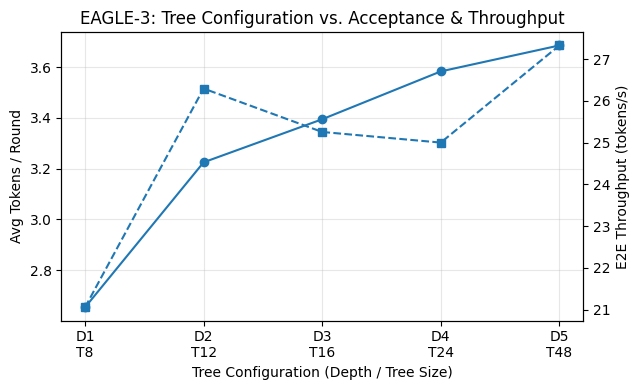

In [42]:
# =====================================================================
# 4-7. Tree Configuration Sweep
#      Depth / Tree Size에 따른 EAGLE 성능 비교
# =====================================================================

configs = [
  (1, 8),
  (2, 12),
  (3, 16),
  (4, 24),
  (5, 48)
]

labels = []
avg_tokens_list = []
tpss = []


for depth, tree_size in configs:

  # EAGLE Tree 설정 변경
  eagle_model.ea_layer.depth = depth

  # ea_layer 내부에서는 root를 제외한 draft node 수를 사용
  eagle_model.ea_layer.total_tokens = tree_size - 1

  # Tree 관련 상태 초기화
  eagle_model.ea_layer.init_tree()
  eagle_model.ea_layer.reset_kv()


  # Warm-up
  _ = eagle_model.eagenerate(
    input_ids,
    temperature=0.0,
    max_new_tokens=8,
    max_length=256
  )


  # Generation 측정
  torch.cuda.synchronize()
  start = time.perf_counter()

  output_ids, n_new, last_round = eagle_model.eagenerate(
    input_ids,
    temperature=0.0,
    max_new_tokens=MAX_NEW,
    max_length=256,
    log=True
  )

  torch.cuda.synchronize()
  elapsed = time.perf_counter() - start


  if torch.is_tensor(n_new):
    n_new = n_new.item()

  generated = output_ids.shape[1] - input_ids.shape[1]
  rounds = last_round + 1

  avg_tokens = n_new / rounds
  tps = generated / elapsed


  labels.append(f"D{depth}\nT{tree_size}")
  avg_tokens_list.append(avg_tokens)
  tpss.append(tps)


  print(
    f"Depth={depth} | "
    f"Tree Size={tree_size:>2} | "
    f"Avg Tokens/Round={avg_tokens:.2f} | "
    f"TPS={tps:.1f}"
  )

# =====================================================================
# Plot
# =====================================================================

x = range(len(configs))

fig, ax1 = plt.subplots(figsize=(6.5, 4))

# 한 Target round에서 확정되는 평균 token 수
ax1.plot(x, avg_tokens_list, "o-")
ax1.set_xticks(x)
ax1.set_xticklabels(labels)
ax1.set_xlabel("Tree Configuration (Depth / Tree Size)")
ax1.set_ylabel("Avg Tokens / Round")
ax1.grid(alpha=0.3)

# Throughput
ax2 = ax1.twinx()
ax2.plot(x, tpss, "s--")
ax2.set_ylabel("E2E Throughput (tokens/s)")

plt.title("EAGLE-3: Tree Configuration vs. Acceptance & Throughput")
plt.tight_layout()
plt.show()

In [43]:
# =====================================================================
# Part 4 종료: GPU 메모리 정리
# =====================================================================

import gc

del eagle_model

gc.collect()
torch.cuda.empty_cache()

print(f"VRAM after cleanup: {torch.cuda.memory_allocated()/1024**3:.2f} GB")

VRAM after cleanup: 0.01 GB


### 관찰

트리를 키우면 $\tau$는 계속 올라가지만 speedup은 그만큼 따라오지 않습니다.
EAGLE 계열의 구조적 한계 때문입니다.

> **깊이를 1 늘릴 때마다 drafter forward가 한 번씩 더 필요합니다.**
> drafting은 여전히 autoregressive이고, 이 sequential 비용이 앞의 속도 식에서 분모를 키웁니다.

"그럼 블록 전체를 **한 번의 forward로** 뽑으면 되지 않나?" — 이것이 다음 파트의 출발점입니다.

# Part 5. DFlash: Parallel Block Drafting [ICML'26]

DFlash는 **block diffusion drafter**를 사용해 여러 미래 토큰을 **한 번의 forward로 병렬 생성**합니다.

* Vanilla SD: draft token을 autoregressive하게 순차 생성
* EAGLE: 여러 candidate를 tree 형태로 생성
* **DFlash: block 전체의 token을 동시에 생성**

```text
[MASK] [MASK] [MASK] [MASK]
          ↓
   DFlash Forward × 1
          ↓
    d1    d2    d3    d4
          ↓
   Target Verification
```

Target은 draft block 전체를 한 번에 검증하고, **앞에서부터 일치하는 prefix만 accept**하므로 최종 결과는 lossless하게 유지됩니다.

본 실습에서는 실제 `Qwen/Qwen3-4B`와 `z-lab/Qwen3-4B-DFlash-b16`을 사용하여 **parallel block drafting과 verification을 구현**하고, Block Size에 따른 **Acceptance Length와 TPS 변화**를 비교합니다.


In [45]:

# =====================================================================
# 5-0. DFlash Setup & Model Load
# =====================================================================

import os
import sys
import torch
import urllib.request
import zipfile
import shutil

DFLASH_DIR = os.path.abspath("dflash-practice")

TARGET_DIR = "/content/models/Qwen3-4B"
DFLASH_MODEL_DIR = "/content/models/Qwen3-4B-DFlash-b16"


# DFlash 코드 준비
if not os.path.exists(DFLASH_DIR):
    url = "https://github.com/kimjongjip/dflash-practice/archive/refs/heads/main.zip"
    zip_path = "dflash-practice.zip"

    urllib.request.urlretrieve(url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(".")

    shutil.move("dflash-practice-main", DFLASH_DIR)
    os.remove(zip_path)

if DFLASH_DIR not in sys.path:
    sys.path.insert(0, DFLASH_DIR)


from dflash.model import dflash_generate
from dflash.practice import (
    load_practice_models,
    stop_token_ids,
    apply_practice_chat_template,
)


# Target / DFlash 모델 로드
target, draft, tokenizer = load_practice_models(
    target_id=TARGET_DIR,
    draft_id=DFLASH_MODEL_DIR,
    device=DEVICE,
    dtype=DTYPE,
)


print("DFlash loaded")
print("Target :", TARGET_DIR)
print("Draft  :", DFLASH_MODEL_DIR)
print("Block  :", draft.block_size)
print("dtype  :", target.dtype)
print(f"VRAM   : {torch.cuda.memory_allocated()/1024**3:.2f} GB")

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

DFlash loaded
Target : /content/models/Qwen3-4B
Draft  : /content/models/Qwen3-4B-DFlash-b16
Block  : 16
dtype  : torch.float16
VRAM   : 8.63 GB


#DFlash의 Block Diffusion Drafting
Vanilla speculative decoding은 draft token을 autoregressive하게 하나씩 생성합니다.
DFlash는 미래 block을 [MASK] token으로 초기화하고, Target hidden state를 context로 사용하여 모든 masked position을 한 번의 denoising forward에서 동시에 예측합니다.

known | [MASK] | [MASK] | ... → DFlash → d1 | d2 | ...

In [46]:
# =====================================================================
# 5-1. [실습] Parallel Block Drafting
#   한 번의 DFlash forward로 여러 draft token을 동시에 생성합니다.
# =====================================================================

import dflash.student_block as student_block


def parallel_block_draft(
  model,
  target_hidden,
  noise_embedding,
  draft_position_ids,
  past_key_values_draft,
  output_head,
  verify_size,
):

  global LAST_DRAFT

  # DFlash drafter를 한 번만 forward
  draft_hidden = model(
    target_hidden=target_hidden,
    noise_embedding=noise_embedding,
    position_ids=draft_position_ids,
    past_key_values=past_key_values_draft,
    use_cache=True,
  )

  # 실제로 제안할 draft token 수
  num_draft = verify_size - 1


  ######################### 실습 시작 ########################

  # To Do: 마지막 num_draft개의 hidden state만 선택하세요.
  draft_hidden = draft_hidden[:, -num_draft:, :]

  # To Do: model.compute_logits()을 사용해 모든 위치의 vocabulary logits을 계산하세요.
  draft_logits = model.compute_logits(draft_hidden, output_head)

  # To Do: torch.argmax()를 사용해 모든 위치의 token을 동시에 선택하세요.
  draft_tokens = torch.argmax(draft_logits, dim=-1)

  ######################### 실습 끝 ########################

  # 첫 번째 draft block만 저장
  if LAST_DRAFT is None:
    LAST_DRAFT = draft_tokens.detach().clone()

  return draft_tokens

  return draft_tokens


# 구현을 DFlash generation에 연결
student_block.parallel_block_draft = parallel_block_draft

In [47]:
# =====================================================================
# 5-2. Parallel Draft 결과 확인
# =====================================================================

PROMPT = "Write a Python function that reverses a linked list."

text = apply_practice_chat_template(
  tokenizer,
  [{"role": "user", "content": PROMPT}]
)

input_ids = tokenizer(
  text,
  return_tensors="pt",
  add_special_tokens=False
).input_ids.to(DEVICE)

eos_ids = stop_token_ids(target, tokenizer)


# 첫 번째 Parallel Draft 저장
LAST_DRAFT = None

_ = dflash_generate(
  model=draft,
  target=target,
  input_ids=input_ids,
  max_new_tokens=16,
  stop_token_ids=eos_ids,
  temperature=0.0,
  block_size=16,
)


print("Draft Shape :", LAST_DRAFT.shape)

print("\n[Parallel Draft]")
print([
  tokenizer.decode([token])
  for token in LAST_DRAFT[0].tolist()
])

Draft Shape : torch.Size([1, 15])

[Parallel Draft]
['!', ' Here', "'s", ' a', ' Python', ' function', ' that', ' revers', 'es', ' a', ' linked', ' list', ' list', '###', "'ll"]


In [48]:
# =====================================================================
# 5-4. Full DFlash Generation
# =====================================================================

MAX_NEW = 128
BLOCK_SIZE = 16

# Warm-up
_ = dflash_generate(
  model=draft,
  target=target,
  input_ids=input_ids,
  max_new_tokens=8,
  stop_token_ids=eos_ids,
  temperature=0.0,
  block_size=BLOCK_SIZE,
)

# DFlash Generation
result = dflash_generate(
  model=draft,
  target=target,
  input_ids=input_ids,
  max_new_tokens=MAX_NEW,
  stop_token_ids=eos_ids,
  temperature=0.0,
  block_size=BLOCK_SIZE,
  return_stats=True,
)

rounds = len(result.acceptance_lengths)
avg_tokens = sum(result.acceptance_lengths) / rounds
tps = 1.0 / result.time_per_output_token

print(f"Block Size       : {BLOCK_SIZE}")
print(f"Generated Tokens : {result.num_output_tokens}")
print(f"Target Rounds    : {rounds}")
print(f"Avg Tokens/Round : {avg_tokens:.2f}")
print(f"Decode TPS       : {tps:.1f} tok/s")

print("\n[Output]")
print(
  tokenizer.decode(
    result.output_ids[0, result.num_input_tokens:],
    skip_special_tokens=True
  )
)

Block Size       : 16
Generated Tokens : 128
Target Rounds    : 18
Avg Tokens/Round : 7.06
Decode TPS       : 60.6 tok/s

[Output]
Sure! Here's a Python function that reverses a **linked list**. We'll assume that the linked list is represented using a `Node` class, where each node has a `value` and a `next` pointer.

### Step 1: Define the Node class

```python
class Node:
    def __init__(self, value):
        self.value = value
        self.next = None
```

### Step 2: Define the function to reverse the linked list

```python
def reverse_linked_list(head):
    prev = None
    current = head

    while current:
        next_node = current


Block Size= 2 | Avg Tokens/Round=1.81 | Decode TPS=16.1
Block Size= 4 | Avg Tokens/Round=3.17 | Decode TPS=28.5
Block Size= 8 | Avg Tokens/Round=4.54 | Decode TPS=34.8
Block Size=12 | Avg Tokens/Round=6.68 | Decode TPS=54.2
Block Size=16 | Avg Tokens/Round=7.06 | Decode TPS=54.9


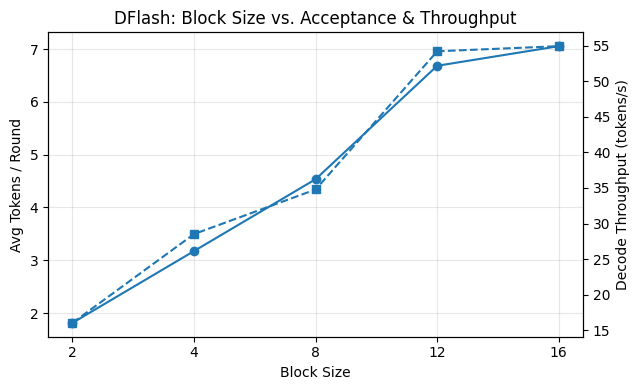

In [49]:
# =====================================================================
# 5-5. Block Size Sweep: Avg Tokens/Round와 Decode TPS 비교
# =====================================================================

import statistics
import matplotlib.pyplot as plt

block_sizes = [2, 4, 8, 12, 16]

avg_tokens_list = []
tpss = []

for block_size in block_sizes:

  # Warm-up
  _ = dflash_generate(
    model=draft,
    target=target,
    input_ids=input_ids,
    max_new_tokens=8,
    stop_token_ids=eos_ids,
    temperature=0.0,
    block_size=block_size,
  )

  # DFlash Generation
  result = dflash_generate(
    model=draft,
    target=target,
    input_ids=input_ids,
    max_new_tokens=MAX_NEW,
    stop_token_ids=eos_ids,
    temperature=0.0,
    block_size=block_size,
    return_stats=True,
  )

  # 결과 계산
  avg_tokens = statistics.mean(result.acceptance_lengths)
  tps = 1.0 / result.time_per_output_token

  avg_tokens_list.append(avg_tokens)
  tpss.append(tps)

  print(
    f"Block Size={block_size:>2} | "
    f"Avg Tokens/Round={avg_tokens:.2f} | "
    f"Decode TPS={tps:.1f}"
  )


# =====================================================================
# Plot
# =====================================================================

x = range(len(block_sizes))

fig, ax1 = plt.subplots(figsize=(6.5, 4))

# 한 Target verification round에서 전진하는 평균 token 수
ax1.plot(x, avg_tokens_list, "o-")
ax1.set_xlabel("Block Size")
ax1.set_ylabel("Avg Tokens / Round")
ax1.set_xticks(x)
ax1.set_xticklabels(block_sizes)
ax1.grid(alpha=0.3)

# Decode Throughput
ax2 = ax1.twinx()
ax2.plot(x, tpss, "s--")
ax2.set_ylabel("Decode Throughput (tokens/s)")

plt.title("DFlash: Block Size vs. Acceptance & Throughput")
plt.tight_layout()
plt.show()

In [50]:
import gc

del target, draft

gc.collect()
torch.cuda.empty_cache()

print(f"VRAM after cleanup: {torch.cuda.memory_allocated()/1024**3:.2f} GB")

VRAM after cleanup: 0.01 GB
